# Branch D — dimension-specific motivation clustering

This notebook clusters the **191 respondents whose validated final active branch is D** using only the four Self-Determination Theory study-experience variables:

1. study motivation type;
2. autonomy in study;
3. competence in the study field; and
4. relatedness at the institution.

It deliberately excludes economic, educational, career, demographic and other dimensions. The result is a motivation/study-experience segmentation, not an overall youth typology.

## Why ordinal Gower distance and K-medoids?

The four answers are ordered categories, not continuous measurements. Their recorded codes preserve the survey order. Gower-style ordinal distance divides each absolute code difference by that question's full theoretical range and averages across the four questions. Consequently:

- every question has equal maximum influence;
- no nominal category receives an invented rank;
- no z-score or one-hot expansion distorts the ordinal steps; and
- cluster centres are actual respondents (medoids), making profiles readable.

Average-linkage hierarchical clustering is used as a robustness comparison. Candidate counts from 2 to 6 are evaluated rather than forcing a predetermined number.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

ROOT = Path.cwd()
VALUES_PATH = ROOT / "outputs/nysc_survey_cleaned_values.csv"
LABELS_PATH = ROOT / "outputs/nysc_survey_cleaned_labels.csv"
OUT = ROOT / "outputs/branch_d_motivation_clusters"
OUT.mkdir(parents=True, exist_ok=True)

VARIABLES = [
    "study_motivation_type",
    "autonomy_in_study",
    "competence_in_study_field",
    "relatedness_at_institution",
]
RANDOM_STATE = 20260823
SUBSAMPLE_REPETITIONS = 100
SUBSAMPLE_FRACTION = 0.80
MIN_CLUSTER_SIZE = 15

print("Output directory:", OUT)

Output directory: /Users/vimashafernando/Desktop/ClusterRP/outputs/branch_d_motivation_clusters


## 1. Reconstruct and verify the strict Branch D cohort

The cohort is rebuilt directly from `branch_routing_source == translated_final_active_branch` and `branch == D`. This prevents entry or intermediate branches from entering the analysis.

In [2]:
values_all = pd.read_csv(VALUES_PATH)
labels_all = pd.read_csv(LABELS_PATH)

strict_mask = (
    values_all["branch"].eq("D")
    & values_all["branch_routing_source"].eq("translated_final_active_branch")
)
values = values_all.loc[strict_mask, [
    "respondent_id", "entry_branch", "branch", "branch_routing_source"
] + VARIABLES].copy()
labels = labels_all[["respondent_id"] + VARIABLES].copy()
cohort = values.merge(labels, on="respondent_id", suffixes=("__code", "__label"), validate="one_to_one")

code_columns = [f"{v}__code" for v in VARIABLES]
validation = {
    "records": int(len(cohort)),
    "unique_respondents": int(cohort["respondent_id"].nunique()),
    "duplicate_ids": int(cohort["respondent_id"].duplicated().sum()),
    "non_D_rows": int(cohort["branch"].ne("D").sum()),
    "wrong_routing_source_rows": int(cohort["branch_routing_source"].ne("translated_final_active_branch").sum()),
    "missing_item_values": int(cohort[code_columns].isna().sum().sum()),
}
assert validation["records"] == 191
assert validation["unique_respondents"] == 191
assert validation["duplicate_ids"] == 0
assert validation["non_D_rows"] == 0
assert validation["wrong_routing_source_rows"] == 0
assert validation["missing_item_values"] == 0

display(pd.Series(validation, name="value").to_frame())

,value
records,191
unique_respondents,191
duplicate_ids,0
non_D_rows,0
wrong_routing_source_rows,0
missing_item_values,0


## 2. Document the readable-to-ordinal mapping

The cleaned numerical values came from the response order in the survey. Lower recorded codes represent more self-determined or more positive study experience. Direction does not affect pairwise distance, but it matters for interpretation. A separate 0–100 positive-orientation score is created only for profile displays.

In [3]:
CANONICAL = {
    "study_motivation_type": {
        1: "Intrinsic: genuinely passionate about the subject",
        2: "Identified: aligned with own goals",
        3: "Introjected: avoid guilt or disappointing family",
        4: "External: qualification required for a job",
        5: "Amotivated/uncertain: following the path ended up on",
    },
    "autonomy_in_study": {
        1: "A great deal of choice and control",
        2: "Some flexibility within a mostly fixed curriculum",
        3: "Very little choice; prescribed and fixed",
        4: "No choice or control",
    },
    "competence_in_study_field": {
        1: "Very capable and confident",
        2: "Fairly capable with some gaps",
        3: "Somewhat capable; struggles in some areas",
        4: "Not very capable; frequently out of depth",
    },
    "relatedness_at_institution": {
        1: "Strongly connected and part of the community",
        2: "Some connections but not deeply involved",
        3: "Weakly connected or isolated",
        4: "No sense of belonging",
    },
}

mapping_rows = []
for variable in VARIABLES:
    observed_pairs = cohort[[f"{variable}__code", f"{variable}__label"]].drop_duplicates()
    for code, canonical_label in CANONICAL[variable].items():
        readable = observed_pairs.loc[
            observed_pairs[f"{variable}__code"].eq(code), f"{variable}__label"
        ].dropna().unique().tolist()
        mapping_rows.append({
            "variable": variable,
            "ordinal_code": code,
            "canonical_interpretation": canonical_label,
            "readable_labels_observed": " | ".join(readable),
            "records": int(cohort[f"{variable}__code"].eq(code).sum()),
        })
mapping_audit = pd.DataFrame(mapping_rows)

for variable in VARIABLES:
    observed_codes = set(cohort[f"{variable}__code"].astype(int).unique())
    assert observed_codes.issubset(CANONICAL[variable].keys())

display(mapping_audit)

,variable,ordinal_code,canonical_interpretation,readable_labels_observed,records
0,study_motivation_type,1,Intrinsic: genuinely passionate about the subject,Because I am genuinely passionate about this s...,59
1,study_motivation_type,2,Identified: aligned with own goals,Because it aligns with my own goals and will l...,72
2,study_motivation_type,3,Introjected: avoid guilt or disappointing family,To avoid disappointing my family or feeling gu...,12
3,study_motivation_type,4,External: qualification required for a job,Because I need the qualification for a job — i...,35
4,study_motivation_type,5,Amotivated/uncertain: following the path ended...,I am not sure why — I am following the path I ...,13
5,autonomy_in_study,1,A great deal of choice and control,A great deal — I have real freedom to shape my...,100
6,autonomy_in_study,2,Some flexibility within a mostly fixed curriculum,Some — there is flexibility within a mostly fi...,68
7,autonomy_in_study,3,Very little choice; prescribed and fixed,Very little — everything is prescribed and fixed,18
8,autonomy_in_study,4,No choice or control,None — I have no say in what or how I study,5
9,competence_in_study_field,1,Very capable and confident,Very capable — confident and effective in my f...,68


## 3. Construct the equal-weight ordinal Gower distance

For item \(j\), distance is \(|x_{ij}-x_{kj}|/(L_j-1)\), where \(L_j\) is the number of ordered response levels. Overall distance is the mean of the four item distances.

In [4]:
X_codes = cohort[code_columns].to_numpy(float)
theoretical_ranges = np.array([len(CANONICAL[v]) - 1 for v in VARIABLES], dtype=float)

item_distance_matrices = []
for j, variable in enumerate(VARIABLES):
    item_distance_matrices.append(
        np.abs(X_codes[:, None, j] - X_codes[None, :, j]) / theoretical_ranges[j]
    )
D = np.mean(item_distance_matrices, axis=0)
np.fill_diagonal(D, 0.0)

assert np.allclose(D, D.T)
assert D.min() >= 0 and D.max() <= 1

distance_audit = pd.DataFrame({
    "variable": VARIABLES,
    "ordered_levels": [len(CANONICAL[v]) for v in VARIABLES],
    "normalising_range": theoretical_ranges,
    "weight_in_total_distance": 0.25,
})
display(distance_audit)
print("Pairwise Gower distance: min", D[np.triu_indices(len(D), 1)].min().round(3),
      "median", np.median(D[np.triu_indices(len(D), 1)]).round(3),
      "max", D.max().round(3))

,variable,ordered_levels,normalising_range,weight_in_total_distance
0,study_motivation_type,5,4.0,0.25
1,autonomy_in_study,4,3.0,0.25
2,competence_in_study_field,4,3.0,0.25
3,relatedness_at_institution,4,3.0,0.25


Pairwise Gower distance: min 0.0 median 0.25 max 0.938


## 4. Evaluate K-medoids candidates and stability

Stability is tested by repeatedly fitting the model to a random 80% subsample, assigning all 191 respondents to the resulting medoids, and comparing that assignment with the full-sample solution using adjusted Rand index (ARI).

In [5]:
def fit_kmedoids(D, k, n_init=200, max_iter=200, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    n = len(D)
    best = None
    for _ in range(n_init):
        medoids = np.sort(rng.choice(n, size=k, replace=False))
        for _ in range(max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            new_medoids = medoids.copy()
            for cluster in range(k):
                members = np.flatnonzero(labels == cluster)
                if len(members) == 0:
                    nearest = D[:, medoids].min(axis=1)
                    available = np.setdiff1d(np.argsort(nearest)[::-1], new_medoids)
                    new_medoids[cluster] = available[0]
                else:
                    within = D[np.ix_(members, members)]
                    new_medoids[cluster] = members[np.argmin(within.sum(axis=1))]
            if np.array_equal(new_medoids, medoids):
                break
            medoids = new_medoids
        labels = np.argmin(D[:, medoids], axis=1)
        loss = float(D[np.arange(n), medoids[labels]].sum())
        candidate = (loss, tuple(medoids.tolist()), medoids.copy(), labels.copy())
        if best is None or candidate[:2] < best[:2]:
            best = candidate
    return {"loss": best[0], "medoids": best[2], "labels": best[3]}


def subsample_stability(D, k, reference_labels, repetitions=100, fraction=0.80, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state + 100 * k)
    n = len(D)
    sample_size = int(np.floor(fraction * n))
    rows = []
    for repetition in range(repetitions):
        idx = np.sort(rng.choice(n, size=sample_size, replace=False))
        sub = fit_kmedoids(
            D[np.ix_(idx, idx)], k, n_init=40,
            random_state=random_state + 1000 * k + repetition,
        )
        global_medoids = idx[sub["medoids"]]
        predicted_all = np.argmin(D[:, global_medoids], axis=1)
        rows.append({
            "k": k,
            "repetition": repetition + 1,
            "ari_vs_full_solution": adjusted_rand_score(reference_labels, predicted_all),
        })
    return pd.DataFrame(rows)


candidate_solutions = {}
candidate_rows = []
stability_parts = []

for k in range(2, 7):
    solution = fit_kmedoids(D, k, n_init=300, random_state=RANDOM_STATE + k)
    labels_k = solution["labels"]
    hierarchical_labels = AgglomerativeClustering(
        n_clusters=k, metric="precomputed", linkage="average"
    ).fit_predict(D)
    stability = subsample_stability(
        D, k, labels_k, SUBSAMPLE_REPETITIONS, SUBSAMPLE_FRACTION
    )
    stability_parts.append(stability)
    sizes = np.bincount(labels_k, minlength=k)
    candidate_solutions[k] = solution
    candidate_rows.append({
        "k": k,
        "silhouette_gower": silhouette_score(D, labels_k, metric="precomputed"),
        "subsample_ari_mean": stability["ari_vs_full_solution"].mean(),
        "subsample_ari_p10": stability["ari_vs_full_solution"].quantile(0.10),
        "hierarchical_ari": adjusted_rand_score(labels_k, hierarchical_labels),
        "minimum_cluster_size": int(sizes.min()),
        "maximum_cluster_size": int(sizes.max()),
        "medoid_loss": solution["loss"],
    })

candidate_metrics = pd.DataFrame(candidate_rows)
stability_results = pd.concat(stability_parts, ignore_index=True)

eligible = candidate_metrics.loc[candidate_metrics["minimum_cluster_size"].ge(MIN_CLUSTER_SIZE)].copy()
if eligible.empty:
    raise RuntimeError("No candidate meets the minimum cluster-size rule.")

eligible["rank_silhouette"] = eligible["silhouette_gower"].rank(ascending=False, method="min")
eligible["rank_stability"] = eligible["subsample_ari_mean"].rank(ascending=False, method="min")
eligible["rank_hierarchical_agreement"] = eligible["hierarchical_ari"].rank(ascending=False, method="min")
eligible["primary_mean_rank"] = eligible[[
    "rank_silhouette", "rank_stability"
]].mean(axis=1)
best_rank = eligible["primary_mean_rank"].min()
selected_k = int(eligible.loc[eligible["primary_mean_rank"].eq(best_rank), "k"].min())

candidate_metrics = candidate_metrics.merge(eligible[["k", "primary_mean_rank"]], on="k", how="left")
candidate_metrics["selected"] = candidate_metrics["k"].eq(selected_k)
display(candidate_metrics.round(4))
print(f"Diagnostic selection: k={selected_k}")

,k,silhouette_gower,subsample_ari_mean,subsample_ari_p10,hierarchical_ari,minimum_cluster_size,maximum_cluster_size,medoid_loss,primary_mean_rank,selected
0,2,0.3133,1.0000,1.0000,-0.0069,76,115,27.2500,2.5,False
1,3,0.3517,0.9386,0.8737,0.0050,46,77,22.1667,1.5,True
2,4,0.3206,0.7666,0.5169,0.2853,35,59,19.7083,2.5,False
3,5,0.3130,0.6600,0.4643,0.2342,23,53,18.1250,4.5,False
4,6,0.3170,0.5878,0.3812,0.1711,23,51,16.4792,4.0,False


Diagnostic selection: k=3


## 5. Create readable motivation profiles

Cluster numbers are reordered from lower to higher mean positive orientation. This is a reproducible presentation order, not a judgement about respondent worth.

In [6]:
selected_solution = candidate_solutions[selected_k]
raw_cluster = selected_solution["labels"]

# Convert codes to 0–100 positive orientation only for profile interpretation.
positive = pd.DataFrame(index=cohort.index)
for j, variable in enumerate(VARIABLES):
    positive[variable] = 100 * (1 - (X_codes[:, j] - 1) / theoretical_ranges[j])
positive["raw_cluster"] = raw_cluster
raw_positive_means = positive.groupby("raw_cluster")[VARIABLES].mean()
raw_order = raw_positive_means.mean(axis=1).sort_values().index.tolist()
raw_to_profile = {int(raw): int(i + 1) for i, raw in enumerate(raw_order)}
profile_id = np.array([raw_to_profile[int(c)] for c in raw_cluster])

individual_silhouette = silhouette_samples(D, raw_cluster, metric="precomputed")
assigned_medoid_index = selected_solution["medoids"][raw_cluster]

assignments = cohort[["respondent_id", "entry_branch", "branch", "branch_routing_source"]].copy()
for variable in VARIABLES:
    assignments[f"{variable}__code"] = cohort[f"{variable}__code"].astype(int)
    assignments[f"{variable}__response"] = assignments[f"{variable}__code"].map(CANONICAL[variable])
assignments["motivation_profile_id"] = profile_id
assignments["individual_silhouette"] = individual_silhouette
assignments["low_confidence_membership"] = individual_silhouette < 0.10
assignments["medoid_respondent_id"] = cohort.iloc[assigned_medoid_index]["respondent_id"].to_numpy()

positive["motivation_profile_id"] = profile_id
profile_positive_means = positive.groupby("motivation_profile_id")[VARIABLES].mean()

def profile_name(pid, row):
    motivation = row["study_motivation_type"]
    other_mean = row[[
        "autonomy_in_study", "competence_in_study_field", "relatedness_at_institution"
    ]].mean()
    if row.min() >= 75:
        description = "highly self-directed, capable and connected"
    elif motivation < 35 and other_mean >= 50:
        description = "externally or uncertainly motivated, with moderate study support"
    elif motivation >= 70 and other_mean >= 55:
        description = "goal-aligned motivation with mixed study confidence and support"
    elif row.mean() >= 55:
        description = "moderately positive but uneven study experience"
    else:
        description = "low self-determination and connection"
    return f"Motivation profile {pid}: {description}"

profile_names = {
    int(pid): profile_name(int(pid), profile_positive_means.loc[pid])
    for pid in profile_positive_means.index
}
assignments["motivation_profile_label"] = assignments["motivation_profile_id"].map(profile_names)

profile_sizes = (
    assignments.groupby(["motivation_profile_id", "motivation_profile_label"], as_index=False)
    .agg(records=("respondent_id", "size"),
         low_confidence_records=("low_confidence_membership", "sum"),
         mean_individual_silhouette=("individual_silhouette", "mean"))
)
profile_sizes["percent"] = 100 * profile_sizes["records"] / len(assignments)

category_rows = []
for variable in VARIABLES:
    temp = (
        assignments.groupby([
            "motivation_profile_id", "motivation_profile_label", f"{variable}__code", f"{variable}__response"
        ]).size().rename("records").reset_index()
    )
    temp["within_profile_percent"] = 100 * temp["records"] / temp.groupby("motivation_profile_id")["records"].transform("sum")
    temp = temp.rename(columns={f"{variable}__code": "ordinal_code", f"{variable}__response": "response"})
    temp.insert(2, "variable", variable)
    category_rows.append(temp)
category_distributions = pd.concat(category_rows, ignore_index=True)

medoid_rows = []
for raw, medoid_index in enumerate(selected_solution["medoids"]):
    pid = raw_to_profile[raw]
    row = {"motivation_profile_id": pid, "motivation_profile_label": profile_names[pid],
           "medoid_respondent_id": cohort.iloc[medoid_index]["respondent_id"]}
    for variable in VARIABLES:
        code = int(cohort.iloc[medoid_index][f"{variable}__code"])
        row[variable] = CANONICAL[variable][code]
    medoid_rows.append(row)
medoid_profiles = pd.DataFrame(medoid_rows).sort_values("motivation_profile_id")

display(profile_sizes.round(3))
display(profile_positive_means.round(2))
display(medoid_profiles)

,motivation_profile_id,motivation_profile_label,records,low_confidence_records,mean_individual_silhouette,percent
0,1,Motivation profile 1: externally or uncertainl...,46,6,0.280,24.084
1,2,Motivation profile 2: goal-aligned motivation ...,77,39,0.209,40.314
2,3,"Motivation profile 3: highly self-directed, ca...",68,0,0.562,35.602


,study_motivation_type,autonomy_in_study,competence_in_study_field,relatedness_at_institution
motivation_profile_id,,,,
1,17.93,68.12,56.52,67.39
2,81.82,71.86,58.87,68.83
3,83.09,95.10,94.12,94.12


,motivation_profile_id,motivation_profile_label,medoid_respondent_id,study_motivation_type,autonomy_in_study,competence_in_study_field,relatedness_at_institution
2,1,Motivation profile 1: externally or uncertainl...,nysc-c386bb4b-e1e2-4302-8bdd-add4bcca014a,External: qualification required for a job,Some flexibility within a mostly fixed curriculum,Fairly capable with some gaps,Some connections but not deeply involved
1,2,Motivation profile 2: goal-aligned motivation ...,nysc-91656981-a2c2-46db-84a2-89ff78907497,Identified: aligned with own goals,Some flexibility within a mostly fixed curriculum,Fairly capable with some gaps,Some connections but not deeply involved
0,3,"Motivation profile 3: highly self-directed, ca...",nysc-f3ecc798-9f85-4113-9479-86dce44d7e8d,Identified: aligned with own goals,A great deal of choice and control,Very capable and confident,Strongly connected and part of the community


## 6. Decide whether the segmentation is usable

The selected candidate is treated as usable for exploratory reporting only if it meets all three primary requirements: Gower silhouette of at least 0.25, mean 80%-subsample ARI of at least 0.70, and at least 15 respondents per cluster. Hierarchical agreement and low-confidence membership are reported as additional cautions.

In [7]:
selected_metrics = candidate_metrics.loc[candidate_metrics["k"].eq(selected_k)].iloc[0]
selected_hierarchical = AgglomerativeClustering(
    n_clusters=selected_k, metric="precomputed", linkage="average"
).fit_predict(D)

quality_checks = pd.DataFrame([
    {"check": "Gower silhouette >= 0.25", "value": selected_metrics["silhouette_gower"], "passed": selected_metrics["silhouette_gower"] >= 0.25},
    {"check": "mean 80% subsample ARI >= 0.70", "value": selected_metrics["subsample_ari_mean"], "passed": selected_metrics["subsample_ari_mean"] >= 0.70},
    {"check": f"minimum cluster size >= {MIN_CLUSTER_SIZE}", "value": selected_metrics["minimum_cluster_size"], "passed": selected_metrics["minimum_cluster_size"] >= MIN_CLUSTER_SIZE},
    {"check": "hierarchical agreement ARI >= 0.60", "value": selected_metrics["hierarchical_ari"], "passed": selected_metrics["hierarchical_ari"] >= 0.60},
    {"check": "low-confidence memberships <= 20%", "value": 100 * assignments["low_confidence_membership"].mean(), "passed": assignments["low_confidence_membership"].mean() <= 0.20},
])
primary_pass = bool(quality_checks.iloc[:3]["passed"].all())
method_robust = bool(quality_checks.loc[
    quality_checks["check"].eq("hierarchical agreement ARI >= 0.60"), "passed"
].iloc[0])
if primary_pass and method_robust:
    status = "Usable as an exploratory motivation segmentation"
elif primary_pass:
    status = "Stable within K-medoids but method-dependent — exploratory use only"
else:
    status = "No sufficiently stable/separated motivation segmentation found"

display(quality_checks.round(3))
print("Status:", status)

,check,value,passed
0,Gower silhouette >= 0.25,0.352,True
1,mean 80% subsample ARI >= 0.70,0.939,True
2,minimum cluster size >= 15,46.000,True
3,hierarchical agreement ARI >= 0.60,0.005,False
4,low-confidence memberships <= 20%,23.560,False


Status: Stable within K-medoids but method-dependent — exploratory use only


## 7. Visualise candidates and selected profiles

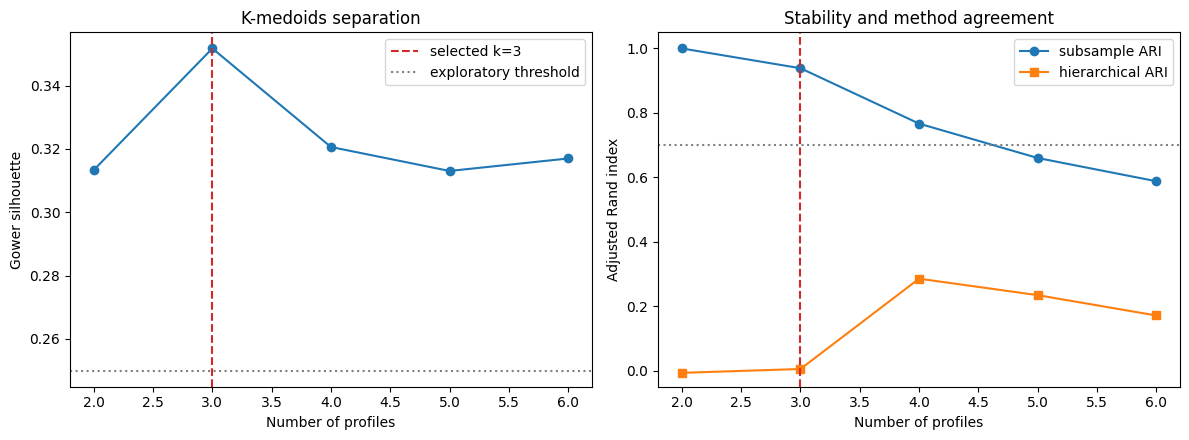

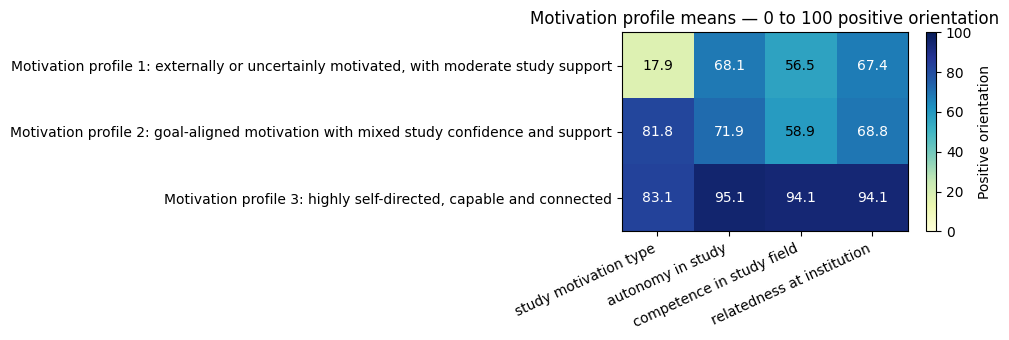

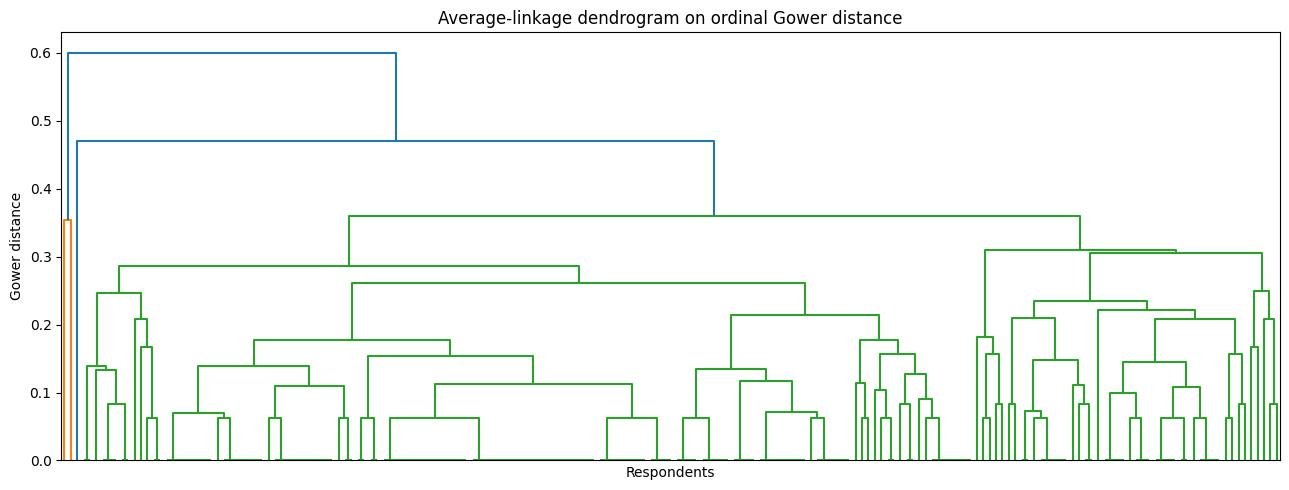

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(candidate_metrics["k"], candidate_metrics["silhouette_gower"], marker="o")
axes[0].axvline(selected_k, linestyle="--", color="tab:red", label=f"selected k={selected_k}")
axes[0].axhline(0.25, linestyle=":", color="grey", label="exploratory threshold")
axes[0].set(title="K-medoids separation", xlabel="Number of profiles", ylabel="Gower silhouette")
axes[0].legend()

axes[1].plot(candidate_metrics["k"], candidate_metrics["subsample_ari_mean"], marker="o", label="subsample ARI")
axes[1].plot(candidate_metrics["k"], candidate_metrics["hierarchical_ari"], marker="s", label="hierarchical ARI")
axes[1].axvline(selected_k, linestyle="--", color="tab:red")
axes[1].axhline(0.70, linestyle=":", color="grey")
axes[1].set(title="Stability and method agreement", xlabel="Number of profiles", ylabel="Adjusted Rand index", ylim=(-0.05, 1.05))
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "motivation_candidate_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, max(3.5, selected_k * 0.8)))
heat = ax.imshow(profile_positive_means.to_numpy(), cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(VARIABLES)), [v.replace("_", " ") for v in VARIABLES], rotation=25, ha="right")
ax.set_yticks(range(selected_k), [profile_names[int(i)] for i in profile_positive_means.index])
for i in range(selected_k):
    for j in range(len(VARIABLES)):
        ax.text(j, i, f"{profile_positive_means.iloc[i, j]:.1f}", ha="center", va="center",
                color="white" if profile_positive_means.iloc[i, j] > 65 else "black")
ax.set_title("Motivation profile means — 0 to 100 positive orientation")
fig.colorbar(heat, ax=ax, label="Positive orientation")
fig.tight_layout()
fig.savefig(OUT / "motivation_profile_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

Z = linkage(squareform(D, checks=True), method="average")
fig, ax = plt.subplots(figsize=(13, 5))
dendrogram(Z, no_labels=True, color_threshold=None, ax=ax)
ax.set(title="Average-linkage dendrogram on ordinal Gower distance", xlabel="Respondents", ylabel="Gower distance")
fig.tight_layout()
fig.savefig(OUT / "motivation_hierarchical_dendrogram.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Save the reproducible outputs

In [9]:
mapping_audit.to_csv(OUT / "motivation_ordinal_mapping_audit.csv", index=False)
distance_audit.to_csv(OUT / "motivation_gower_distance_audit.csv", index=False)
candidate_metrics.to_csv(OUT / "motivation_candidate_metrics.csv", index=False)
stability_results.to_csv(OUT / "motivation_subsample_stability.csv", index=False)
assignments.to_csv(OUT / "motivation_cluster_assignments.csv", index=False)
profile_sizes.to_csv(OUT / "motivation_profile_sizes.csv", index=False)
profile_positive_means.to_csv(OUT / "motivation_profile_positive_means.csv")
category_distributions.to_csv(OUT / "motivation_profile_category_distributions.csv", index=False)
medoid_profiles.to_csv(OUT / "motivation_medoid_profiles.csv", index=False)
quality_checks.to_csv(OUT / "motivation_quality_checks.csv", index=False)

summary = {
    "cohort": {
        "records": int(len(assignments)),
        "branch": "D",
        "routing_source": "translated_final_active_branch",
        "complete_four_item_rows": int(cohort[code_columns].notna().all(axis=1).sum()),
    },
    "dimension": "motivation and study experience",
    "variables": VARIABLES,
    "method": {
        "distance": "equal-weight ordinal Gower",
        "primary_algorithm": "multiple-start K-medoids",
        "comparison_algorithm": "average-linkage hierarchical clustering",
        "candidate_k": [2, 3, 4, 5, 6],
        "selection_rule": "lowest equal-weight rank across K-medoids Gower silhouette and 80% subsample stability; hierarchical agreement is a sensitivity diagnostic",
        "subsample_repetitions": SUBSAMPLE_REPETITIONS,
        "subsample_fraction": SUBSAMPLE_FRACTION,
    },
    "selected_candidate": {
        "k": selected_k,
        "silhouette_gower": float(selected_metrics["silhouette_gower"]),
        "subsample_ari_mean": float(selected_metrics["subsample_ari_mean"]),
        "subsample_ari_p10": float(selected_metrics["subsample_ari_p10"]),
        "hierarchical_ari": float(selected_metrics["hierarchical_ari"]),
        "profile_sizes": {str(int(r.motivation_profile_id)): int(r.records) for r in profile_sizes.itertuples()},
        "profile_names": {str(k): v for k, v in profile_names.items()},
        "low_confidence_memberships": int(assignments["low_confidence_membership"].sum()),
    },
    "quality": {
        "primary_checks_passed": primary_pass,
        "hierarchical_robustness_passed": method_robust,
        "checks_passed": int(quality_checks["passed"].sum()),
        "checks_total": int(len(quality_checks)),
        "status": status,
    },
}
with open(OUT / "motivation_clustering_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved files:")
for path in sorted(OUT.iterdir()):
    print(" -", path.name)

{
  "cohort": {
    "records": 191,
    "branch": "D",
    "routing_source": "translated_final_active_branch",
    "complete_four_item_rows": 191
  },
  "dimension": "motivation and study experience",
  "variables": [
    "study_motivation_type",
    "autonomy_in_study",
    "competence_in_study_field",
    "relatedness_at_institution"
  ],
  "method": {
    "distance": "equal-weight ordinal Gower",
    "primary_algorithm": "multiple-start K-medoids",
    "comparison_algorithm": "average-linkage hierarchical clustering",
    "candidate_k": [
      2,
      3,
      4,
      5,
      6
    ],
    "selection_rule": "lowest equal-weight rank across K-medoids Gower silhouette and 80% subsample stability; hierarchical agreement is a sensitivity diagnostic",
    "subsample_repetitions": 100,
    "subsample_fraction": 0.8
  },
  "selected_candidate": {
    "k": 3,
    "silhouette_gower": 0.35172802787566665,
    "subsample_ari_mean": 0.9385816123977874,
    "subsample_ari_p10": 0.873734105523

## Interpretation guardrails

- These clusters describe only the four motivation/study-experience responses.
- They do not measure economic resources, career direction, educational capital or overall programme suitability.
- Ordinal steps are treated as equally spaced for distance; this is a transparent modelling assumption, not a psychometric fact.
- If the primary separation and stability rules fail, retain the output only as a diagnostic and report that the dimension behaves more like a continuum than distinct types.